# Diabetes Prediction using Machine Learning

**Project:** Diabetes Prediction  
**Dataset:** `Diabetes.csv`  
**Goal:** Predict whether a patient is likely to have diabetes using clinical measurements.

### Workflow
1. Import libraries
2. Load and inspect the dataset
3. Clean the data
4. Exploratory Data Analysis
5. Prepare features and target
6. Train/test split
7. Feature scaling
8. Train multiple ML models
9. Compare model performance
10. Select a model
11. Test predictions for a new patient
12. Save the trained model

In [1]:
# CELL 1 — Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, RocCurveDisplay
)

import joblib

print("Libraries imported successfully.")

Libraries imported successfully.


In [10]:
# CELL 2 — Load the dataset

df = pd.read_csv("diabetes (2).xls")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [11]:
# CELL 3 — Basic dataset information

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  -----

## Expected columns

The standard Pima Indians Diabetes dataset normally contains:

- `Pregnancies`
- `Glucose`
- `BloodPressure`
- `SkinThickness`
- `Insulin`
- `BMI`
- `DiabetesPedigreeFunction`
- `Age`
- `Outcome`

`Outcome` is the target:
- `0` = No diabetes
- `1` = Diabetes

In [12]:
# CELL 4 — Make column names consistent

df.columns = [col.strip() for col in df.columns]

# If your CSV uses lowercase/space variations, this maps common names
# to the standard names without changing the actual data values.
rename_map = {
    "pregnancies": "Pregnancies",
    "glucose": "Glucose",
    "bloodpressure": "BloodPressure",
    "blood pressure": "BloodPressure",
    "skinthickness": "SkinThickness",
    "skin thickness": "SkinThickness",
    "insulin": "Insulin",
    "bmi": "BMI",
    "diabetespedigreefunction": "DiabetesPedigreeFunction",
    "diabetes pedigree function": "DiabetesPedigreeFunction",
    "age": "Age",
    "outcome": "Outcome"
}

normalized = {}
for col in df.columns:
    key = col.strip().lower()
    normalized[col] = rename_map.get(key, col)

df = df.rename(columns=normalized)

print(df.columns.tolist())

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [13]:
# CELL 5 — Check the target column

if "Outcome" not in df.columns:
    raise ValueError(
        "Outcome column was not found. Please check your Diabetes.csv column names."
    )

print(df["Outcome"].value_counts())
print("\nTarget percentages:")
print(df["Outcome"].value_counts(normalize=True) * 100)

Outcome
0    500
1    268
Name: count, dtype: int64

Target percentages:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [14]:
# CELL 6 — Data cleaning

feature_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]

missing_features = [c for c in feature_columns if c not in df.columns]

if missing_features:
    raise ValueError(f"Missing expected columns: {missing_features}")

# In this dataset, zero is not physiologically meaningful for several
# measurements. Treat those zeros as missing so the pipeline can impute them.
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in zero_as_missing:
    df[col] = df[col].replace(0, np.nan)

print("Missing values after treating invalid zeros as missing:")
display(df[feature_columns].isnull().sum())

print("\nTarget values:")
print(df["Outcome"].value_counts())

Missing values after treating invalid zeros as missing:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


Target values:
Outcome
0    500
1    268
Name: count, dtype: int64


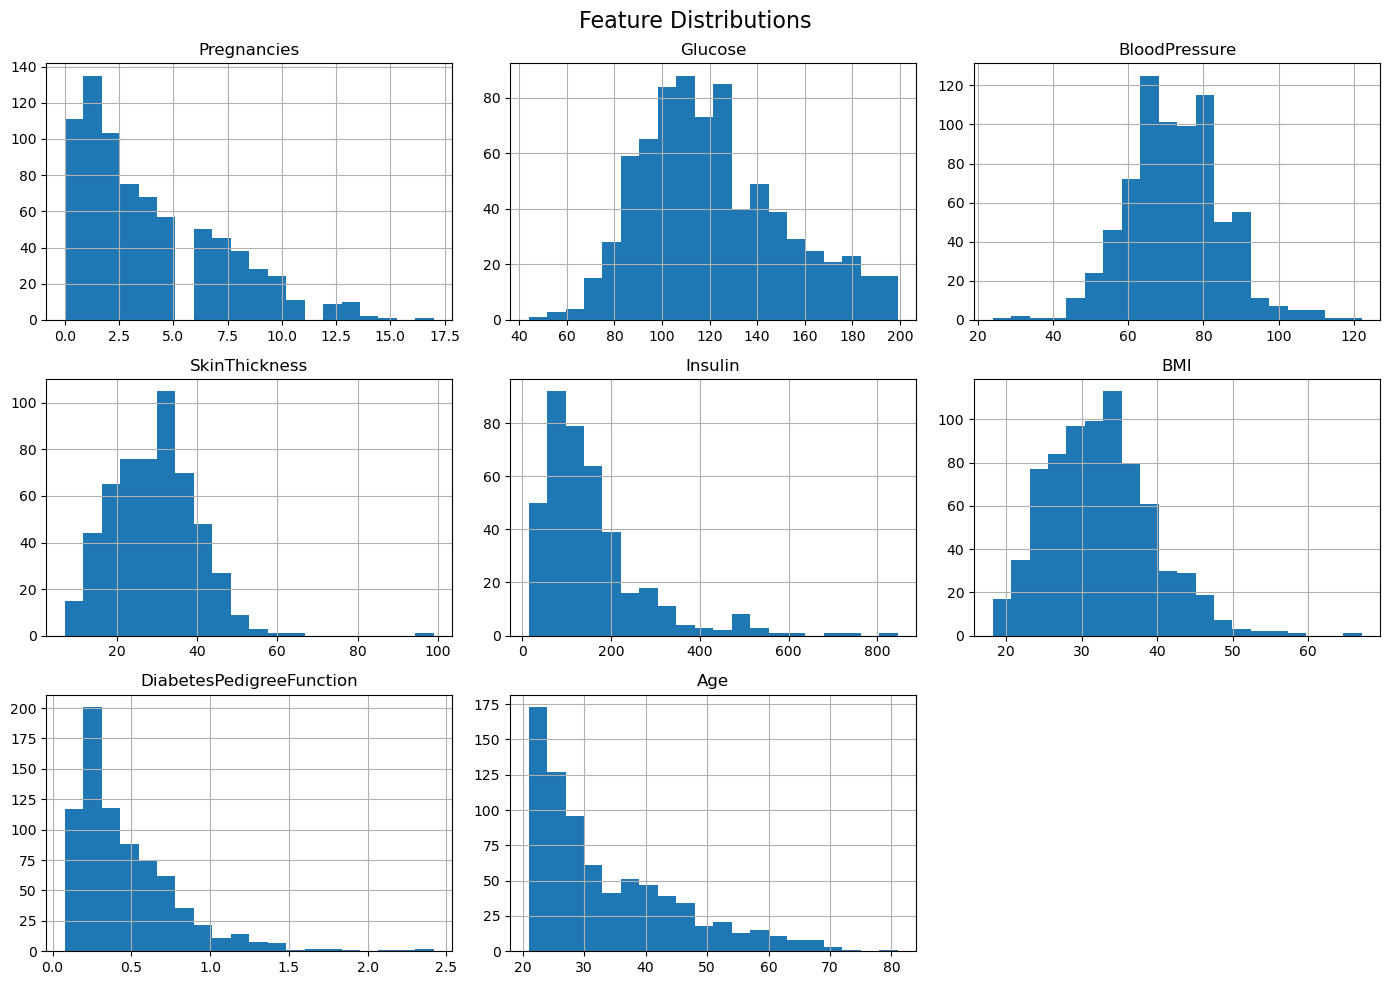

In [15]:
# CELL 7 — Exploratory Data Analysis: distributions

df[feature_columns].hist(figsize=(14, 10), bins=20)
plt.suptitle("Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

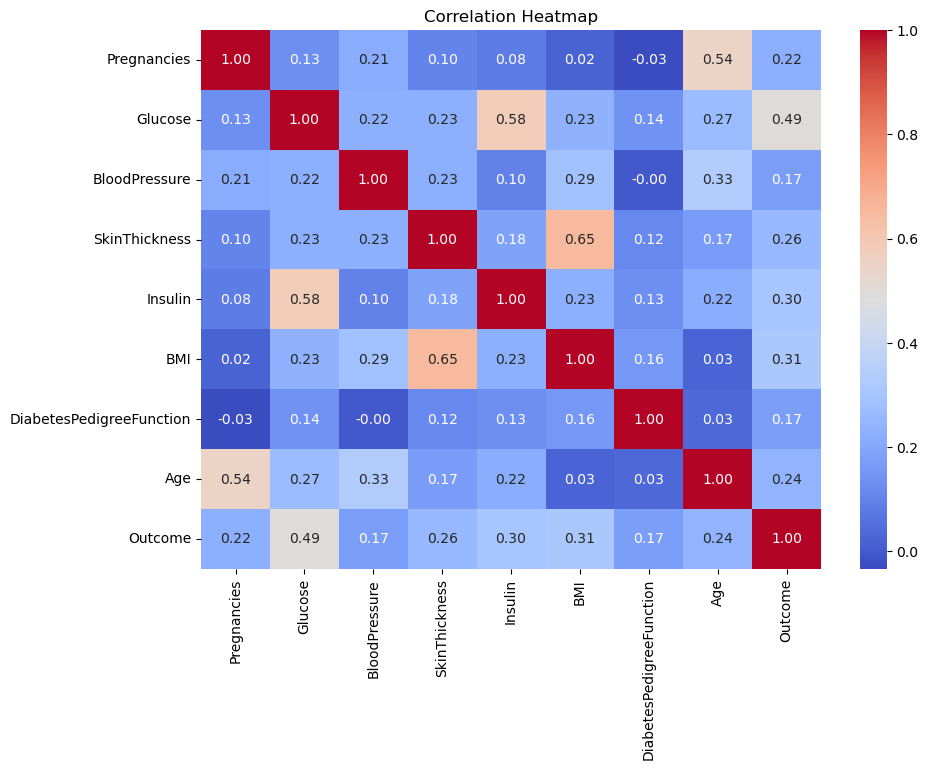

In [16]:
# CELL 8 — Correlation heatmap

plt.figure(figsize=(10, 7))
sns.heatmap(df[feature_columns + ["Outcome"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

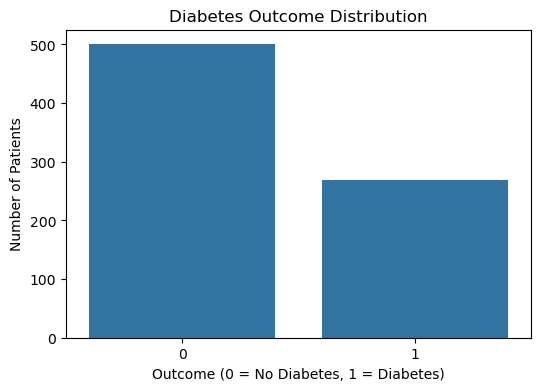

In [17]:
# CELL 9 — Outcome distribution

plt.figure(figsize=(6, 4))
sns.countplot(x="Outcome", data=df)
plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.show()

In [18]:
# CELL 10 — Prepare X and y

X = df[feature_columns]
y = df["Outcome"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [19]:
# CELL 11 — Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


## Why scaling is used

Models such as Logistic Regression and KNN work better when numerical features are on comparable scales. The `StandardScaler` is therefore placed inside each pipeline.

The imputer and scaler are fitted only on the training data through the pipeline, which helps avoid data leakage.

In [22]:
# CELL 12 — Define machine learning models

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=8,
            random_state=42
        ))
    ])
}

print("Models created:")

for name in models:
    print("-", name)

Models created:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest


In [23]:
# CELL 13 — Train and evaluate all models

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        y_prob = None

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Decision Tree,0.7597,0.6393,0.7222,0.6783,0.7622
1,KNN,0.7532,0.6600,0.6111,0.6346,0.7899
3,Random Forest,0.7532,0.6818,0.5556,0.6122,0.8141
0,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130


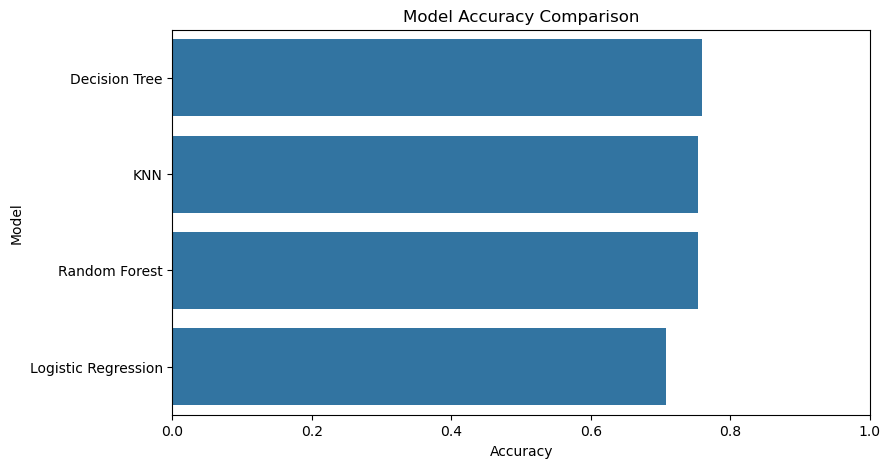

In [24]:
# CELL 14 — Compare model accuracy

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Accuracy", y="Model")
plt.xlim(0, 1)
plt.title("Model Accuracy Comparison")
plt.show()

In [25]:
# CELL 15 — Choose a model

# For a reproducible project, we use Logistic Regression as the final
# interpretable baseline model. You can change this to another model
# after reviewing the comparison table above.

final_model_name = "Logistic Regression"
final_model = models[final_model_name]

print("Final model:", final_model_name)

Final model: Logistic Regression


In [26]:
# CELL 16 — Detailed evaluation of final model

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

Accuracy : 0.7078
Precision: 0.6
Recall   : 0.5
F1 Score : 0.5455
ROC AUC  : 0.813

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



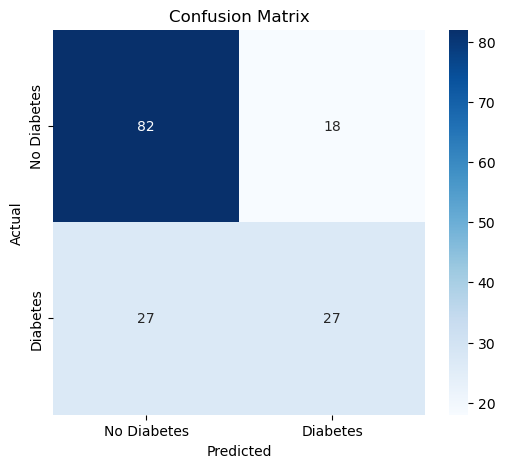

In [27]:
# CELL 17 — Confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

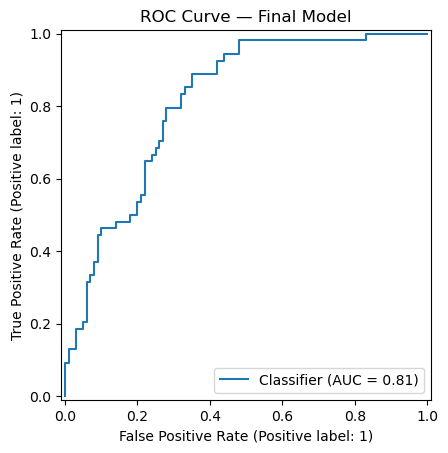

In [28]:
# CELL 18 — ROC curve

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve — Final Model")
plt.show()

In [29]:
# CELL 19 — Feature coefficients for Logistic Regression

# The pipeline's final estimator is Logistic Regression.
logistic_model = final_model.named_steps["model"]

coefficients = pd.DataFrame({
    "Feature": feature_columns,
    "Coefficient": logistic_model.coef_[0]
}).sort_values("Coefficient", ascending=False)

display(coefficients)

,Feature,Coefficient
1,Glucose,1.182567
5,BMI,0.688652
0,Pregnancies,0.377446
6,DiabetesPedigreeFunction,0.233337
7,Age,0.147794
3,SkinThickness,0.028321
2,BloodPressure,-0.044111
4,Insulin,-0.066119


## Single-patient prediction

Enter values for one patient in the same order as the training features.

**Important:** This is a machine-learning demonstration, not a medical diagnosis. A real clinical decision must be made by a qualified healthcare professional.

In [30]:
# CELL 20 — Predict for a new patient

def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree_function,
    age
):
    patient = pd.DataFrame([{
        "Pregnancies": pregnancies,
        "Glucose": glucose,
        "BloodPressure": blood_pressure,
        "SkinThickness": skin_thickness,
        "Insulin": insulin,
        "BMI": bmi,
        "DiabetesPedigreeFunction": diabetes_pedigree_function,
        "Age": age
    }])

    prediction = final_model.predict(patient)[0]
    probability = final_model.predict_proba(patient)[0, 1]

    result = "Diabetes predicted" if prediction == 1 else "No diabetes predicted"

    return result, probability


# Example patient
result, probability = predict_diabetes(
    pregnancies=2,
    glucose=120,
    blood_pressure=70,
    skin_thickness=25,
    insulin=80,
    bmi=30.5,
    diabetes_pedigree_function=0.40,
    age=35
)

print("Prediction:", result)
print("Estimated probability:", round(probability * 100, 2), "%")

Prediction: No diabetes predicted
Estimated probability: 20.86 %


In [31]:
# CELL 21 — Interactive prediction form

import ipywidgets as widgets
from IPython.display import display, clear_output

preg = widgets.FloatText(value=2, description="Pregnancies:")
glu = widgets.FloatText(value=120, description="Glucose:")
bp = widgets.FloatText(value=70, description="Blood Pressure:")
skin = widgets.FloatText(value=25, description="Skin Thickness:")
ins = widgets.FloatText(value=80, description="Insulin:")
bmi_w = widgets.FloatText(value=30.5, description="BMI:")
dpf = widgets.FloatText(value=0.40, description="Pedigree:")
age_w = widgets.FloatText(value=35, description="Age:")

button = widgets.Button(description="Predict Diabetes")
output = widgets.Output()

def on_predict_clicked(_):
    with output:
        clear_output()
        result, probability = predict_diabetes(
            preg.value, glu.value, bp.value, skin.value,
            ins.value, bmi_w.value, dpf.value, age_w.value
        )
        print("Prediction:", result)
        print("Estimated probability:", round(probability * 100, 2), "%")

button.on_click(on_predict_clicked)

display(
    preg, glu, bp, skin, ins, bmi_w, dpf, age_w,
    button, output
)

FloatText(value=2.0, description='Pregnancies:')

FloatText(value=120.0, description='Glucose:')

FloatText(value=70.0, description='Blood Pressure:')

FloatText(value=25.0, description='Skin Thickness:')

FloatText(value=80.0, description='Insulin:')

FloatText(value=30.5, description='BMI:')

FloatText(value=0.4, description='Pedigree:')

FloatText(value=35.0, description='Age:')

Button(description='Predict Diabetes', style=ButtonStyle())

Output()

In [32]:
# CELL 22 — Save the trained model

joblib.dump(final_model, "diabetes_prediction_model.pkl")
print("Model saved as diabetes_prediction_model.pkl")

Model saved as diabetes_prediction_model.pkl


In [33]:
# CELL 23 — Load the saved model and test it

loaded_model = joblib.load("diabetes_prediction_model.pkl")

test_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 30.5,
    "DiabetesPedigreeFunction": 0.40,
    "Age": 35
}])

loaded_prediction = loaded_model.predict(test_patient)[0]
loaded_probability = loaded_model.predict_proba(test_patient)[0, 1]

print("Loaded model prediction:", loaded_prediction)
print("Loaded model probability:", round(loaded_probability * 100, 2), "%")

Loaded model prediction: 0
Loaded model probability: 20.86 %


# Final Project Summary

### Problem
Diabetes is a common health condition. The project uses patient-related numerical measurements to build a machine-learning classification model.

### Input
- Pregnancies
- Glucose
- Blood Pressure
- Skin Thickness
- Insulin
- BMI
- Diabetes Pedigree Function
- Age

### Output
- `0` → No diabetes predicted
- `1` → Diabetes predicted

### Machine-learning techniques
- Data cleaning
- Exploratory Data Analysis
- Train/test split
- Missing-value imputation
- Standardization
- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- Accuracy, Precision, Recall, F1-score and ROC-AUC
- Confusion Matrix
- ROC Curve
- Individual prediction
- Model saving/loading

**Note:** This project is for educational/internship demonstration and is not a medical diagnostic system.

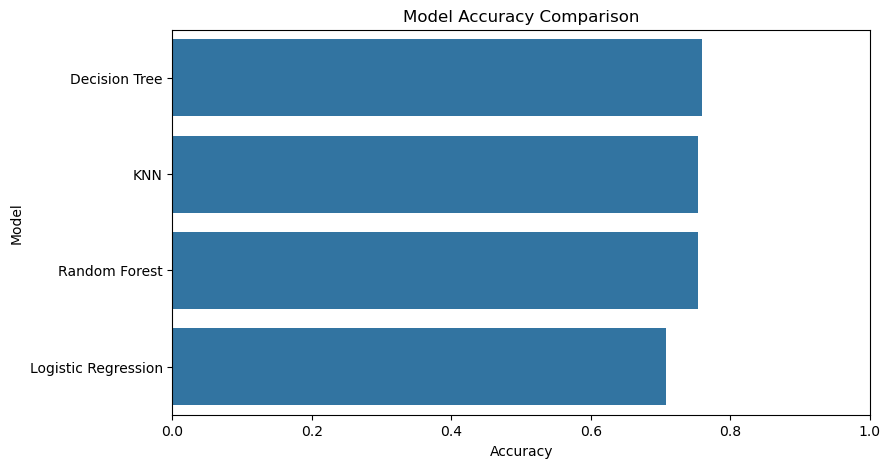

In [34]:
# CELL 14 — Compare model accuracy

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.xlim(0, 1)
plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.show()

In [35]:
# DIABETES PREDICTION DASHBOARD

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# Title
display(HTML("""
<h1 style="text-align:center;">🩺 Diabetes Prediction Dashboard</h1>
<p style="text-align:center;">
Enter the patient's details and click <b>Predict Diabetes</b>.
</p>
"""))

# Input fields
preg = widgets.FloatText(
    value=2,
    description="Pregnancies:"
)

glu = widgets.FloatText(
    value=120,
    description="Glucose:"
)

bp = widgets.FloatText(
    value=70,
    description="Blood Pressure:"
)

skin = widgets.FloatText(
    value=25,
    description="Skin Thickness:"
)

ins = widgets.FloatText(
    value=80,
    description="Insulin:"
)

bmi = widgets.FloatText(
    value=30.5,
    description="BMI:"
)

dpf = widgets.FloatText(
    value=0.40,
    description="Pedigree:"
)

age = widgets.FloatText(
    value=35,
    description="Age:"
)

# Button
predict_button = widgets.Button(
    description="Predict Diabetes",
    button_style="primary"
)

output = widgets.Output()

# Prediction function
def make_prediction(button):

    with output:
        clear_output()

        patient = pd.DataFrame([{
            "Pregnancies": preg.value,
            "Glucose": glu.value,
            "BloodPressure": bp.value,
            "SkinThickness": skin.value,
            "Insulin": ins.value,
            "BMI": bmi.value,
            "DiabetesPedigreeFunction": dpf.value,
            "Age": age.value
        }])

        prediction = final_model.predict(patient)[0]
        probability = final_model.predict_proba(patient)[0][1]

        print("====================================")
        print("       DIABETES PREDICTION")
        print("====================================")

        if prediction == 1:
            print("Prediction: Diabetes predicted")
        else:
            print("Prediction: No diabetes predicted")

        print(
            "Estimated probability:",
            round(probability * 100, 2),
            "%"
        )

        print("====================================")


predict_button.on_click(make_prediction)

# Display dashboard
display(preg)
display(glu)
display(bp)
display(skin)
display(ins)
display(bmi)
display(dpf)
display(age)

display(predict_button)
display(output)

FloatText(value=2.0, description='Pregnancies:')

FloatText(value=120.0, description='Glucose:')

FloatText(value=70.0, description='Blood Pressure:')

FloatText(value=25.0, description='Skin Thickness:')

FloatText(value=80.0, description='Insulin:')

FloatText(value=30.5, description='BMI:')

FloatText(value=0.4, description='Pedigree:')

FloatText(value=35.0, description='Age:')

Button(button_style='primary', description='Predict Diabetes', style=ButtonStyle())

Output()